# 09 - Final test on 2025

Everything before this notebook used 2022 to 2024. This is the only place 2025 is used. I fixed the model settings, the cleaning rules and the simulator design on the earlier seasons, trained on 2022 to 2024, and ran this once. Nothing below was tuned on it. The one place I looked at a 2025 result and tried an idea afterwards is labelled.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from f1lab.evaluate import hazard_results, lap_time_results, simulator_results

STAGE = "final"   # train 2022-2024, test 2025
raw = pd.read_parquet("../data/laps.parquet")
clean = pd.read_parquet("../data/laps_clean.parquet")
Path("../reports").mkdir(exist_ok=True)

## Lap-time model

In [2]:
lt = lap_time_results(raw, clean, STAGE)
print(f"{lt['n_laps']} laps from {lt['n_races']} races; tracks with no training data: {lt['unseen_tracks'] or 'none'}")
lt["metrics"].round(3)

20807 laps from 21 races; tracks with no training data: none


,MAE (s),RMSE (s)
predict no change,0.894,1.550
mean by compound,0.876,1.537
mean by compound and tyre age,0.870,1.532
linear (robust),0.637,1.379
gradient boosting,0.621,1.370


Gradient boosting reaches 0.621 s mean absolute error on 2025, the linear model 0.637 and the best simple baseline 0.870. That makes it about 29% better than the baseline, close to what 2024 showed (0.599 against 0.855, about 30%). The edge over the linear model is smaller this time, 0.016 s against 0.030 s. Every 2025 track appeared in training, so there's no unseen-track number this year.

In [3]:
lt["by_seen"].round(3)

,seen tracks,unseen tracks
linear (robust),0.637,NaN
gradient boosting,0.621,NaN


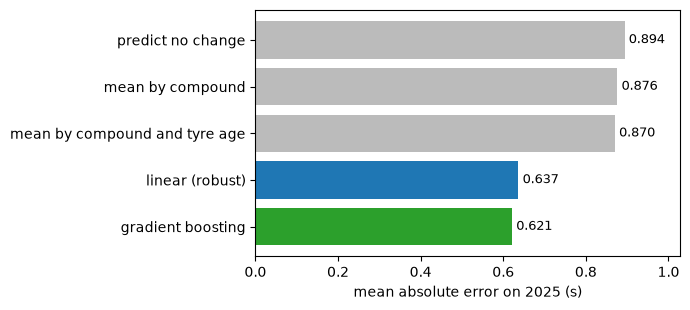

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.2))
m = lt["metrics"]["MAE (s)"]
ax.barh(m.index, m.values, color=["#bbb", "#bbb", "#bbb", "tab:blue", "tab:green"])
for i, v in enumerate(m.values):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlabel("mean absolute error on 2025 (s)"); ax.set_xlim(0, m.max() * 1.15)
plt.tight_layout(); plt.savefig("../reports/lap_time_mae.png", dpi=150); plt.show()

## Intervals

In [5]:
lt["intervals"].round(3)

,coverage,mean width (s),"coverage, seen tracks","coverage, unseen tracks"
0.5,0.526,0.889,0.526,NaN
0.8,0.814,1.802,0.814,NaN
0.9,0.914,2.554,0.914,NaN


The intervals hold up on a season the model never saw. The 50% interval contains 52.6% of laps, the 80% one 81.4% and the 90% one 91.4%, and the 80% interval is about 1.8 s wide on average. This is the result I trust most in the project.

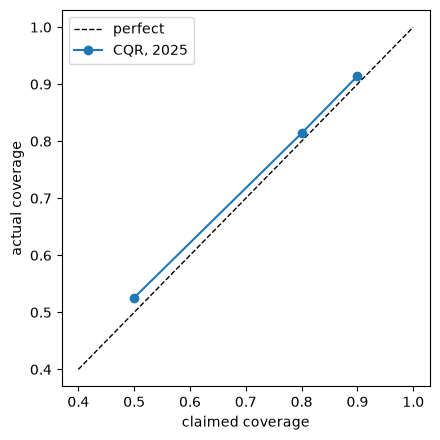

In [6]:
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0.4, 1], [0.4, 1], "k--", lw=1, label="perfect")
ax.plot(lt["intervals"].index, lt["intervals"]["coverage"], "o-", label="CQR, 2025")
ax.set_xlabel("claimed coverage"); ax.set_ylabel("actual coverage"); ax.legend()
plt.tight_layout(); plt.savefig("../reports/interval_calibration.png", dpi=150); plt.show()

## Safety cars

In [7]:
hz = hazard_results(raw, clean, STAGE)
print(f"rates fitted on 2022-2024: laps 1-2 {hz['rates'][0]:.3f} per lap, later {hz['rates'][1]:.4f} per lap")
hz["summary"].round(4)

rates fitted on 2022-2024: laps 1-2 0.124 per lap, later 0.0152 per lap


log loss, one rate for every lap     0.0917
log loss, laps 1-2 split             0.0845
expected events per race             1.1511
actual events per race               1.0476
races                               21.0000
events                              22.0000
dtype: float64

The two-rate model scores better than a single rate (log loss 0.0845 against 0.0917). It expects 1.15 safety car or VSC starts per race and there were 1.05 (22 in 21 races), so the average is about right. 2024 was a quiet year with 0.62 per race, so the swing from year to year is large. This is a decent average rate and nothing more.

## Race simulator

In [8]:
sm = simulator_results(raw, clean, STAGE)
print(f"{sm['driver_races']} driver-races from {sm['races']} races")
print(f"just base pace x laps: median abs error {sm['naive'].abs().median():.1f} s, mean error {sm['naive'].mean():.1f} s")
sm["table"].round(3)

276 driver-races from 20 races
just base pace x laps: median abs error 164.0 s, mean error 167.2 s


,simulator,constant pace
median abs error (s),30.301,28.116
mean error (s),-11.247,-13.585
RMSE (s),56.480,54.473
inside 80% interval,0.656,0.721
rank agreement within races,0.827,0.843


The simulator did worse here than on 2024. The median error is 30.3 s on a race of about 5,500 s, against 18.1 s on 2024, and the 80% interval holds only 65.6% of results. A version with no tyre or fuel effect does slightly better (28.1 s, 72.1% inside) and ranks drivers a bit better within a race (0.843 against 0.827). So on this test the tyre model doesn't earn its place in the race total. Guessing base pace times laps misses by 164 s, so modelling pit stops and safety car laps is still doing a lot of the work.

In [9]:
full = sm["replay"]
by = full.groupby(pd.cut(full["neutral laps"], [-1, 0, 5, 10, 100], labels=["none", "1-5", "6-10", "over 10"]), observed=True)
by_neutral = by.agg(driver_races=("error", "size"), median_abs_error=("error", lambda s: s.abs().median()),
                    mean_error=("error", "mean"), inside_80=("inside", "mean")).round(2)
by_neutral

,driver_races,median_abs_error,mean_error,inside_80
neutral laps,,,,
none,83,14.63,-14.06,0.77
1-5,124,43.66,9.26,0.54
6-10,34,47.36,-15.19,0.79
over 10,35,61.57,-73.39,0.66


As on 2024, races with no safety car laps are the easiest (median error 14.6 s, 77% inside the 80% interval). Error grows once there are safety cars, to 61.6 s in races with more than ten neutralised laps. The worst coverage is in the one-to-five-lap bucket, where only 54% of results land inside the interval.

In [10]:
sm["coverage"].round(3).rename("share inside the interval")

50%    0.417
80%    0.656
90%    0.775
Name: share inside the interval, dtype: float64

Claimed 50%, 80% and 90% intervals contain 41.7%, 65.6% and 77.5% of results. The intervals are too narrow.

In [11]:
quiet = full[full["neutral laps"] == 0]
rng = np.random.default_rng(0)
rows = {}
for stops, g in quiet.groupby("stops"):
    boots = [rng.choice(g["error"].to_numpy(), len(g)).mean() for _ in range(2000)]
    rows[f"{stops} stop"] = {"driver-races": len(g), "mean error (s)": g["error"].mean(),
                             "low": np.quantile(boots, .05), "high": np.quantile(boots, .95)}
pd.DataFrame(rows).T.round(1)

,driver-races,mean error (s),low,high
1 stop,70.0,-16.4,-19.5,-13.3
2 stop,13.0,-1.4,-11.2,9.8


In races without a neutralisation, one-stoppers finished 16.4 s faster than predicted. Two-stoppers were about on target (1.4 s faster, but there are only 13 of them and the range is wide). So in 2025 the simulator was too pessimistic about one-stop races, the opposite of the small bias on 2024, and it would lean toward recommending more stops than were needed.

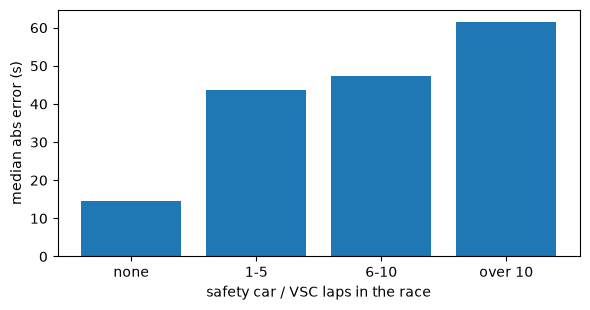

In [12]:
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(by_neutral.index.astype(str), by_neutral["median_abs_error"])
ax.set_xlabel("safety car / VSC laps in the race"); ax.set_ylabel("median abs error (s)")
plt.tight_layout(); plt.savefig("../reports/simulator_error_by_safety_car.png", dpi=150); plt.show()

## A check after the fact

In [13]:
from f1lab.features import drying_races, wet_races
from f1lab.race_costs import pit_stops

skip = drying_races(clean) | wet_races(raw)
dry = raw[[(s, r) not in skip for s, r in zip(raw["season"], raw["round"])]]
stops = pit_stops(dry)
stops.groupby(["season", "status"])["loss"].median().unstack("status").round(1)

status,green,sc,vsc
season,,,
2022,22.5,23.7,16.8
2023,22.7,17.3,21.2
2024,22.8,12.5,15.7
2025,22.2,10.5,16.1


Green-flag stops cost the same every year (22.2 to 22.8 s). Stops under a safety car or VSC have not: 23.7 s in 2022, then 17.3, 12.5 and 10.5 s. The simulator averages over all its training seasons (a median of 18.4 s), so I wondered whether that drift explained the 2025 miss.

In [14]:
# what if safety car stop costs had been learned from 2024 only? (decided after seeing the result above)
late = simulator_results(raw, clean, STAGE, recent_neutral_stops=True)
under = pd.DataFrame({"frozen simulator": sm["table"]["simulator"], "stop costs from 2024 only": late["table"]["simulator"]})
under.loc["inside 50% interval"] = [sm["coverage"]["50%"], late["coverage"]["50%"]]
under.loc["inside 90% interval"] = [sm["coverage"]["90%"], late["coverage"]["90%"]]
under.round(3)

,frozen simulator,stop costs from 2024 only
median abs error (s),30.301,29.702
mean error (s),-11.247,-10.339
RMSE (s),56.480,55.801
inside 80% interval,0.656,0.659
rank agreement within races,0.827,0.829
inside 50% interval,0.417,0.417
inside 90% interval,0.775,0.783


It doesn't. Learning safety car stop costs from 2024 only moves the median error from 30.3 s to 29.7 s and leaves coverage where it was (65.9% against 65.6%). I tried this after seeing the result, so it isn't a tuned model, and it didn't help anyway.

### Where the error sits

In [15]:
per_race = full.groupby(["round", "track"]).agg(
    driver_races=("error", "size"), mean_error=("error", "mean"),
    neutral_laps=("neutral laps", "first"), inside_80=("inside", "mean")).round(1)
sq = per_race["mean_error"] ** 2 * per_race["driver_races"]
print(f"spread of the average error between races (sd): {full.groupby('round')['error'].mean().std():.1f} s")
print(f"spread between drivers inside one race (sd):    {(full['error'] - full.groupby('round')['error'].transform('mean')).std():.1f} s")
print(f"share of the squared error from the 3 worst races: {sq.nlargest(3).sum() / sq.sum():.0%}")
ordered = per_race.sort_values("mean_error")
pd.concat([ordered.head(3), ordered.tail(3)])

spread of the average error between races (sd): 51.7 s
spread between drivers inside one race (sd):    22.4 s
share of the squared error from the 3 worst races: 60%


,,driver_races,mean_error,neutral_laps,inside_80
round,track,,,,
15,Zandvoort,17,-111.4,15,0.3
4,Sakhir,19,-87.7,4,0.3
9,Catalunya,17,-69.0,6,0.6
17,Baku,17,64.7,4,0.2
5,Jeddah,14,80.6,3,0.0
8,Monte Carlo,5,83.0,3,0.0


The error mostly sits at the race level. The average error differs between races by about 52 s (standard deviation), while drivers inside one race differ from each other by about 22 s, and the three worst races carry 60% of the squared error. The actual race was 111 s quicker than predicted at Zandvoort and 83 s slower at Monte Carlo.

Those shifts are shared by every driver in a race, so they should matter less when comparing strategies inside one race. But they're what keeps the total-time intervals from being honest. The simulator doesn't know how a particular race's safety cars will play out (where the field bunches up, when the pit lane is open), and an average can't capture that. The next thing I'd try is letting the safety car costs vary per race with a shared random effect, so the intervals widen where they should.

## Summary

What held up on the test season: the lap-time model (about 29% better than the best simple baseline), its intervals (80% claimed, 81.4% observed) and the safety car rate. What didn't: the simulator's total-time intervals (80% claimed, 65.6% observed), and the tyre model adds nothing to the race total compared with constant pace.

## Saved numbers

In [16]:
summary = {
    "laps_test": lt["n_laps"], "races_test": lt["n_races"],
    **{f"mae_{k.replace(' ', '_')}": v for k, v in lt["metrics"]["MAE (s)"].items()},
    **{f"coverage_{lvl}": lt["intervals"].loc[lvl, "coverage"] for lvl in lt["intervals"].index},
    **{f"width_{lvl}": lt["intervals"].loc[lvl, "mean width (s)"] for lvl in lt["intervals"].index},
    "sc_log_loss_baseline": hz["summary"]["log loss, one rate for every lap"],
    "sc_log_loss_model": hz["summary"]["log loss, laps 1-2 split"],
    "sc_expected_per_race": hz["summary"]["expected events per race"], "sc_actual_per_race": hz["summary"]["actual events per race"],
    **{f"sim_{k.replace(' ', '_')}": v for k, v in sm["table"]["simulator"].items()},
    **{f"flat_{k.replace(' ', '_')}": v for k, v in sm["table"]["constant pace"].items()},
    "sim_naive_median_abs_error": float(sm["naive"].abs().median()),
    **{f"sim_coverage_{k}": v for k, v in sm["coverage"].items()},
}
out = pd.Series(summary)
out.to_csv("../reports/final_results.csv", header=["value"])
out.round(4)

laps_test                            20807.0000
races_test                              21.0000
mae_predict_no_change                    0.8938
mae_mean_by_compound                     0.8764
mae_mean_by_compound_and_tyre_age        0.8703
mae_linear_(robust)                      0.6369
mae_gradient_boosting                    0.6214
coverage_0.5                             0.5258
coverage_0.8                             0.8141
coverage_0.9                             0.9142
width_0.5                                0.8891
width_0.8                                1.8022
width_0.9                                2.5537
sc_log_loss_baseline                     0.0917
sc_log_loss_model                        0.0845
sc_expected_per_race                     1.1511
sc_actual_per_race                       1.0476
sim_median_abs_error_(s)                30.3013
sim_mean_error_(s)                     -11.2471
sim_RMSE_(s)                            56.4800
sim_inside_80%_interval                 